# 第五轮（正式结果）：MoSSP 口径，三个问题

Fast LRALM 的参数比例按定理取，rho、原始步长常数和 alpha in {1/6, 0.3, 0.5, 0.8} 由网格选出；选出的 alpha 统一给 Smoothed GDA 与 Perturbed Smoothed GDA；附录另报两个基线各自最优 alpha 的结果。基线其余关键参数各从 4 个候选值中选。在第一个初始点上选参，再从 5 个初始点运行。运行时选 A100，按顺序运行全部单元格；结果文件名带 `_r5`。


In [1]:
# 1. 检查算力与基础环境
import os, platform, subprocess, time, json, itertools, warnings
import numpy as np
import torch
import torch.nn.functional as F

warnings.filterwarnings("ignore")
print("Host:", platform.node(), "| Python:", platform.python_version(), "| CPUs:", os.cpu_count())
res = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True)
print("GPU:", res.stdout.strip() if res.returncode == 0 else "No GPU (CPU runtime)")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64  # float64 avoids 1e-6 precision floor for KKT residuals
print(f"PyTorch: {torch.__version__} | device={DEVICE} | dtype={DTYPE}")

Host: 433d5f1d5c19 | Python: 3.13.16 | CPUs: 12
GPU: NVIDIA A100-SXM4-80GB, 81920 MiB
PyTorch: 2.14.1+cu130 | device=cuda | dtype=torch.float64


In [2]:
# 2. 输出/缓存目录与全局实验参数
if os.path.isdir("/content"):  # Colab runtime (browser or IDE extension)
    DATA_DIR = "/content/data"
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/3_DDLALM_exp"
    except Exception as e:
        print("Drive not mounted:", type(e).__name__)
        OUT_DIR = "/content/3_DDLALM_exp"
else:
    OUT_DIR = os.path.abspath("results")
    DATA_DIR = os.path.abspath("data")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
print("OUT_DIR:", OUT_DIR, "| DATA_DIR:", DATA_DIR)

SEED = 0
SEEDS = [0, 1, 2, 3, 4]   # five initial points; the problem data are fixed
ILL_EPS = 1e-5       # IllCondL1 target KKT accuracy (first round)
ILL_BUDGET = 15000   # oracle call budget for IllCondL1 (first round)
ILL_SIGMAS = [1e-2, 1e-3]
WB_EPS = 1e-3        # Waterbirds Group DRO target KKT accuracy
WB_BUDGET = 4000     # oracle call budget for Waterbirds
MN_EPS = 1e-4        # MNIST mNPC target KKT accuracy
MN_BUDGET = 4000     # oracle call budget for MNIST mNPC
BATCH_SIZE = 128 if DEVICE.type == "cuda" else 16

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT_DIR: /content/drive/MyDrive/3_DDLALM_exp | DATA_DIR: /content/data


In [3]:
# 3. 数据集自动下载与预处理缓存
import tarfile, urllib.request, csv, shutil
from PIL import Image
import torchvision
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader

# WILDS mirror of Waterbirds (same metadata.csv: img_filename, y, place, split); nlp.stanford.edu is unreachable
WATERBIRDS_URL = "https://worksheets.codalab.org/rest/bundles/0x505056d5cdea4e4eaa0e242cbfe2daa4/contents/blob/"


class _ImageListDataset(Dataset):
    def __init__(self, root, filenames, tfm):
        self.root, self.filenames, self.tfm = root, filenames, tfm

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.root, self.filenames[idx])).convert("RGB")
        return self.tfm(img)


def load_waterbirds_features(cache_dir=OUT_DIR, data_dir=DATA_DIR, proj_dim=32):
    """Download Waterbirds (Sagawa et al. 2020), extract ImageNet-pretrained ResNet18
    features on the training split, project to R^{32} via fixed PCA, and cache."""
    cache_path = os.path.join(cache_dir, f"waterbirds_resnet18_{proj_dim}d.npz")
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        print(f"[Waterbirds] Loaded cached features from {cache_path}: shape={d['A'].shape}")
        return d["A"], d["b"], d["groups"]

    wb_root = os.path.join(data_dir, "waterbird_complete95_forest2water2")
    tar_path = os.path.join(data_dir, "waterbird_complete95_forest2water2.tar.gz")
    if not os.path.exists(os.path.join(wb_root, "metadata.csv")):
        if os.path.exists(tar_path) and os.path.getsize(tar_path) < 10**6:
            os.remove(tar_path)  # drop an empty or partial download
        if not os.path.exists(tar_path):
            print("[Waterbirds] Downloading tarball from the WILDS CodaLab mirror...")
            if shutil.which("wget"):
                subprocess.run(["wget", "-q", "--show-progress", "-O", tar_path, WATERBIRDS_URL], check=True)
            else:
                urllib.request.urlretrieve(WATERBIRDS_URL, tar_path)
        print("[Waterbirds] Extracting tarball...")
        os.makedirs(wb_root, exist_ok=True)
        with tarfile.open(tar_path, "r:gz") as tf:
            tf.extractall(wb_root)  # the WILDS tarball has no top-level folder

    filenames, labels, groups = [], [], []
    with open(os.path.join(wb_root, "metadata.csv"), "r") as f:
        for row in csv.DictReader(f):
            if int(row["split"]) == 0:  # official training split (4795 images)
                y = int(row["y"])
                place = int(row["place"])
                filenames.append(row["img_filename"])
                labels.append(1.0 if y == 1 else -1.0)
                groups.append(2 * y + place)

    tfm = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    ds = _ImageListDataset(wb_root, filenames, tfm)
    loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=min(4, os.cpu_count() or 2),
                        pin_memory=(DEVICE.type == "cuda"))

    print(f"[Waterbirds] Extracting ResNet18 features for {len(ds)} images on {DEVICE}...")
    t0 = time.time()
    backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    backbone.fc = torch.nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    feats = []
    with torch.no_grad():
        for xb in loader:
            feats.append(backbone(xb.to(DEVICE, non_blocking=True)).cpu().numpy())
    X512 = np.concatenate(feats, axis=0).astype(np.float64)
    print(f"[Waterbirds] Feature extraction done in {time.time() - t0:.1f}s")

    # Fixed projection R^512 -> R^32 via top-32 PCA on centered training features, standardized
    X_centered = X512 - X512.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(X_centered, full_matrices=False)
    A = X_centered @ Vt[:proj_dim].T
    A = A / (np.std(A, axis=0, keepdims=True) + 1e-8) / np.sqrt(proj_dim)
    b = np.array(labels, dtype=np.float64)
    g = np.array(groups, dtype=np.int64)
    np.savez(cache_path, A=A, b=b, groups=g)
    print(f"[Waterbirds] Cached to {cache_path} | group counts={[int((g == k).sum()) for k in range(4)]}")
    return A, b, g


def load_mnist_mnpc(cache_dir=OUT_DIR, data_dir=DATA_DIR, digits=(1, 2, 3, 4), noise_std=1.0, seed=SEED, rescale=False):
    """Load MNIST digits (GDPA §5 & F.1: digit 1 prioritized, m=3 secondary digits 2,3,4),
    add i.i.d. N(0, noise_std^2) pixel noise, scale by 1/sqrt(784), and cache."""
    tag = "".join(str(d) for d in digits)
    cache_path = os.path.join(cache_dir, f"mnist_mnpc_d{tag}_s{seed}{'_scaled' if rescale else '_raw'}.npz")
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        X_list = [d[f"X_{c}"] for c in range(len(digits))]
        print(f"[MNIST mNPC] Loaded cached data from {cache_path}: counts={[x.shape[0] for x in X_list]}")
        return X_list

    ds = torchvision.datasets.MNIST(root=data_dir, train=True, download=True)
    imgs = ds.data.numpy().astype(np.float64).reshape(-1, 784) / 255.0
    targets = ds.targets.numpy()
    rng = np.random.default_rng(seed)
    X_list = []
    for dig in digits:
        Xc = imgs[targets == dig].copy()
        if noise_std > 0:
            Xc += rng.normal(0.0, noise_std, size=Xc.shape)
        if rescale:
            Xc /= np.sqrt(784.0)
        X_list.append(Xc)
    np.savez(cache_path, **{f"X_{c}": Xc for c, Xc in enumerate(X_list)})
    print(f"[MNIST mNPC] Cached to {cache_path} | class counts={[x.shape[0] for x in X_list]}")
    return X_list

In [4]:
# 4. GPU 向量化问题类（同时支持单点与批量 B 组超参并行求值）+ 解析雅可比自动校验

def proj_simplex_batch(V):
    """Exact Euclidean projection onto the unit simplex along the last dimension."""
    U, _ = torch.sort(V, dim=-1, descending=True)
    css = torch.cumsum(U, dim=-1) - 1.0
    ind = torch.arange(1, V.shape[-1] + 1, device=V.device, dtype=V.dtype)
    cond = U - css / ind > 0
    rho = cond.sum(dim=-1, keepdim=True).clamp(min=1)
    theta = css.gather(-1, rho - 1) / rho.to(V.dtype)
    return torch.clamp(V - theta, min=0.0)


def estimate_smoothness(P, radius=1.5, n_probes=24, seed=0):
    """Estimate local effective (L_f, L_A, G_A) around init_x for grid scaling."""
    gen = torch.Generator(device=P.device).manual_seed(seed)
    x0 = P.init_x()
    dirs = torch.randn((n_probes, P.n), generator=gen, device=P.device, dtype=P.dtype)
    dirs = dirs / dirs.norm(dim=-1, keepdim=True).clamp(min=1e-12)
    radii = torch.linspace(0.05, radius, n_probes, device=P.device, dtype=P.dtype)[:, None]
    X1 = x0[None, :] + radii * dirs
    X2 = X1 + 1e-3 * dirs
    _, J1, gf1 = P.oracle(X1)
    _, J2, gf2 = P.oracle(X2)
    dx = (X2 - X1).norm(dim=-1)
    G_A = torch.linalg.matrix_norm(J1, ord=2).max().item()
    L_A = (torch.linalg.matrix_norm(J2 - J1, ord=2) / dx).max().item()
    L_f = ((gf2 - gf1).norm(dim=-1) / dx).max().item()
    return max(L_f, 1e-6), max(L_A, 1e-6), max(G_A, 1e-6)


class WaterbirdsGroupDRO:
    """Waterbirds Group DRO (Zhang-Xu §6.2) cast in our unconstrained composite class:
        min_{theta in R^137}  f(theta) + max_{g=1..4} A_g(theta)
    where s_theta(a) = v^T tanh(W^T a + u) + c, W in R^{32x4}, u,v in R^4, c in R,
    A_g(theta) = mean_{j in I_g} log(1 + exp(-b_j s_theta(a_j))),
    f(theta)   = lam_reg * (sqrt(1 + ||theta - theta0||^2) - 1)   (smooth, globally Lipschitz;
    centered at the initial point so that theta = 0 is not a KKT point).
    """

    def __init__(self, A_np, b_np, groups_np, hidden=4, lam_reg=1e-2, seed=SEED,
                 device=DEVICE, dtype=DTYPE):
        self.device, self.dtype = device, dtype
        self.d = A_np.shape[1]
        self.H = hidden
        self.m = 4
        self.n = self.d * hidden + hidden + hidden + 1  # 137 for d=32, hidden=4
        self.lam_reg = float(lam_reg)
        self.seed = seed

        # Split samples by group for exact, zero-waste per-group GEMMs
        self.A_grp, self.b_grp = [], []
        for g in range(self.m):
            mask = (groups_np == g)
            self.A_grp.append(torch.tensor(A_np[mask], device=device, dtype=dtype))
            self.b_grp.append(torch.tensor(b_np[mask], device=device, dtype=dtype))

        self.L_h = 1.0
        self.D_Y = float(np.sqrt(2.0))
        self.x0 = self.init_x()
        self.L_f, self.L_A, self.G_A = estimate_smoothness(self, radius=1.5)

    def init_x(self):
        rng = np.random.default_rng(self.seed)
        x0 = rng.normal(0.0, 0.1, size=self.n)
        return torch.tensor(x0, device=self.device, dtype=self.dtype)

    def proj(self, V):
        return proj_simplex_batch(V)

    def L_Dx(self, rho):
        return self.L_f + self.L_A * self.L_h + rho * (self.G_A ** 2)

    def _unpack(self, X):
        B, d, H = X.shape[0], self.d, self.H
        W = X[:, :d * H].reshape(B, d, H)
        u = X[:, d * H:d * H + H]
        v = X[:, d * H + H:d * H + 2 * H]
        c = X[:, d * H + 2 * H:]  # (B, 1)
        return W, u, v, c

    def oracle(self, X):
        """Batched oracle O_{f,A}(X). X: (B, n) -> A: (B, 4), J: (B, 4, n), gf: (B, n)."""
        squeeze = (X.ndim == 1)
        if squeeze:
            X = X.unsqueeze(0)
        B, d, H = X.shape[0], self.d, self.H
        W, u, v, c = self._unpack(X)
        W_mat = W.permute(1, 0, 2).reshape(d, B * H)  # (d, B*H)

        A_out = torch.empty((B, self.m), device=self.device, dtype=self.dtype)
        J_out = torch.empty((B, self.m, self.n), device=self.device, dtype=self.dtype)

        for g in range(self.m):
            Ag, bg = self.A_grp[g], self.b_grp[g]
            Ng = Ag.shape[0]
            Z = (Ag @ W_mat).reshape(Ng, B, H).permute(1, 0, 2) + u[:, None, :]  # (B, Ng, H)
            Ha = torch.tanh(Z)
            s = (Ha * v[:, None, :]).sum(dim=-1) + c                             # (B, Ng)
            neg_bs = -s * bg[None, :]
            A_out[:, g] = F.softplus(neg_bs).mean(dim=1)

            w = (-bg[None, :] * torch.sigmoid(neg_bs)) / float(Ng)               # (B, Ng)
            D = (1.0 - Ha * Ha) * v[:, None, :]                                  # (B, Ng, H)
            WD = w[:, :, None] * D                                               # (B, Ng, H)
            # J_W: (B, d, H) via single GEMM (d, Ng) @ (Ng, B*H)
            JW = (Ag.T @ WD.permute(1, 0, 2).reshape(Ng, B * H)).reshape(d, B, H).permute(1, 0, 2)
            Ju = WD.sum(dim=1)
            Jv = (w[:, :, None] * Ha).sum(dim=1)
            Jc = w.sum(dim=1, keepdim=True)
            J_out[:, g, :d * H] = JW.reshape(B, d * H)
            J_out[:, g, d * H:d * H + H] = Ju
            J_out[:, g, d * H + H:d * H + 2 * H] = Jv
            J_out[:, g, d * H + 2 * H:] = Jc

        Dx = X - self.x0
        norm2 = (Dx * Dx).sum(dim=-1, keepdim=True)
        gf = self.lam_reg * Dx / torch.sqrt(1.0 + norm2)
        if squeeze:
            return A_out[0], J_out[0], gf[0]
        return A_out, J_out, gf

    def objective_single(self, x):
        W, u, v, c = self._unpack(x.unsqueeze(0))
        W, u, v, c = W[0], u[0], v[0], c[0]
        vals = []
        for g in range(self.m):
            s = torch.tanh(self.A_grp[g] @ W + u) @ v + c[0]
            vals.append(F.softplus(-self.b_grp[g] * s).mean())
        A_vec = torch.stack(vals)
        f_val = self.lam_reg * (torch.sqrt(1.0 + ((x - self.x0) ** 2).sum()) - 1.0)
        return f_val, A_vec


    @torch.no_grad()
    def metrics(self, x):
        """Objective f(theta) + max_g A_g(theta) (worst-group loss); no original constraint."""
        A, _, _ = self.oracle(x)
        f_val = self.lam_reg * (torch.sqrt(1.0 + ((x - self.x0) ** 2).sum()) - 1.0)
        return (f_val + A.max()).item(), float("nan")


class MNISTmNPC:
    """Multi-class Neyman-Pearson Classification on MNIST (GDPA §5 & F.1) with exact penalty:
        min_{W in R^{4x784}}  phi_0(W) + lam_reg*(sqrt(1+||W||_F^2)-1) + gamma_pen * sum_{j=1}^3 max(phi_j(W)-r, 0)
    where phi_c(W) = (1/(m |X_c|)) sum_{xi in X_c} sum_{i != c} sigmoid(-(w_c - w_i)^T xi).
    """

    def __init__(self, X_list, r_thresh=0.1, gamma_pen=5.0, lam_reg=1e-2, seed=SEED,
                 device=DEVICE, dtype=DTYPE):
        self.device, self.dtype = device, dtype
        self.C = len(X_list)            # m + 1 = 4 classes
        self.m = self.C - 1             # m = 3 constraint classes
        self.d = X_list[0].shape[1]     # 784
        self.n = self.C * self.d        # 3136
        self.r_thresh = float(r_thresh)
        self.gamma_pen = float(gamma_pen)
        self.lam_reg = float(lam_reg)
        self.seed = seed

        self.X_cls = [torch.tensor(Xc, device=device, dtype=dtype) for Xc in X_list]
        self.L_h = float(gamma_pen * np.sqrt(self.m))
        self.D_Y = float(gamma_pen * np.sqrt(self.m))
        self.L_f, self.L_A, self.G_A = estimate_smoothness(self, radius=1.5)

    def init_x(self):
        rng = np.random.default_rng(self.seed)
        x0 = rng.normal(0.0, 1e-3, size=self.n)  # matches GDPA F.1
        return torch.tensor(x0, device=self.device, dtype=self.dtype)

    def proj(self, V):
        """prox_{rho h^*} = projection onto [0, gamma_pen]^m."""
        return torch.clamp(V, 0.0, self.gamma_pen)

    def L_Dx(self, rho):
        return self.L_f + self.L_A * self.L_h + rho * (self.G_A ** 2)

    def _phi_and_grad(self, c, W_mat, B):
        Xc = self.X_cls[c]  # (Nc, d)
        Nc = Xc.shape[0]
        # U: (B, Nc, C) via single GEMM (Nc, d) @ (d, B*C)
        U = (Xc @ W_mat).reshape(Nc, B, self.C).permute(1, 0, 2)
        margin = U[:, :, c:c + 1] - U               # (B, Nc, C); col c is 0
        S = torch.sigmoid(-margin)                  # (B, Nc, C)
        S[:, :, c] = 0.0
        val = S.sum(dim=(1, 2)) / float(self.m * Nc)

        G = S * (1.0 - S) / float(self.m * Nc)      # (B, Nc, C); col c is 0
        G[:, :, c] = -G.sum(dim=2)
        # grad_W: (B, C, d) via single GEMM (B*C, Nc) @ (Nc, d)
        grad = (G.permute(0, 2, 1).reshape(B * self.C, Nc) @ Xc).reshape(B, self.n)
        return val, grad

    def oracle(self, X):
        """Batched oracle O_{f,A}(X). X: (B, n) -> A: (B, m), J: (B, m, n), gf: (B, n)."""
        squeeze = (X.ndim == 1)
        if squeeze:
            X = X.unsqueeze(0)
        B = X.shape[0]
        W_mat = X.reshape(B * self.C, self.d).T  # (d, B*C)

        _, g0 = self._phi_and_grad(0, W_mat, B)
        norm2 = (X * X).sum(dim=-1, keepdim=True)
        gf = g0 + self.lam_reg * X / torch.sqrt(1.0 + norm2)

        A_out = torch.empty((B, self.m), device=self.device, dtype=self.dtype)
        J_out = torch.empty((B, self.m, self.n), device=self.device, dtype=self.dtype)
        for j in range(self.m):
            vj, gj = self._phi_and_grad(j + 1, W_mat, B)
            A_out[:, j] = vj - self.r_thresh
            J_out[:, j, :] = gj

        if squeeze:
            return A_out[0], J_out[0], gf[0]
        return A_out, J_out, gf

    def objective_single(self, x):
        W = x.reshape(self.C, self.d)
        vals = []
        for c in range(self.C):
            U = self.X_cls[c] @ W.T
            S = torch.sigmoid(-(U[:, c:c + 1] - U))
            mask = torch.ones(self.C, device=self.device, dtype=self.dtype)
            mask[c] = 0.0
            vals.append((S * mask).sum() / float(self.m * self.X_cls[c].shape[0]))
        f_val = vals[0] + self.lam_reg * (torch.sqrt(1.0 + (x * x).sum()) - 1.0)
        A_vec = torch.stack(vals[1:]) - self.r_thresh
        return f_val, A_vec


@torch.no_grad()
def _mnist_metrics(self, x):
    """Objective phi_0(W) + regularizer and violation ||(phi_j(W) - r)_+|| of the original constraints."""
    W_mat = x.unsqueeze(0).reshape(self.C, self.d).T
    v0, _ = self._phi_and_grad(0, W_mat, 1)
    A, _, _ = self.oracle(x)
    reg = self.lam_reg * (torch.sqrt(1.0 + (x * x).sum()) - 1.0)
    return (v0[0] + reg).item(), torch.clamp(A, min=0.0).norm().item()


MNISTmNPC.metrics = _mnist_metrics


class IllCondL1:
    """min_x f(x) + ||B x - c||_1 with ill-conditioned B.
    f(x) = 1/2 sum_l log(1 + (x_l - d_l)^2) >= 0   (nonconvex, |f'| <= 1/2, |f''| <= 1)
    B = U diag(sigma) V^T, sigma from 1 to sigma_min; d is chosen so that grad f(x*) = -B^T lam*,
    hence (x*, lam*) is a KKT pair with ||lam*||_inf < 1. The instance is fixed (data seed 0);
    `seed` only changes the initial point."""

    def __init__(self, n=50, m=20, sigma_min=1e-2, seed=SEED, device=DEVICE, dtype=DTYPE):
        rng = np.random.default_rng(0)
        U, _ = np.linalg.qr(rng.normal(size=(m, m)))
        V, _ = np.linalg.qr(rng.normal(size=(n, m)))
        sig = np.logspace(0, np.log10(sigma_min), m)
        B = U @ np.diag(sig) @ V.T
        x_star = rng.normal(size=n)
        lam_star = rng.uniform(-1, 1, size=m)
        target = -B.T @ lam_star
        scale = min(0.4 / np.abs(target).max(), 0.9 / np.abs(lam_star).max())
        target, lam_star = scale * target, scale * lam_star
        t = (1 - np.sqrt(1 - 4 * target ** 2)) / (2 * target)
        self.device, self.dtype, self.seed = device, dtype, seed
        self.n, self.m = n, m
        self.B = torch.tensor(B, device=device, dtype=dtype)
        self.c = torch.tensor(B @ x_star, device=device, dtype=dtype)
        self.d = torch.tensor(x_star - t, device=device, dtype=dtype)
        self.G_A, self.L_A, self.L_f, self.L_h = float(sig[0]), 0.0, 1.0, float(np.sqrt(m))
        self.D_Y = 2.0 * float(np.sqrt(m))

    def init_x(self):
        rng = np.random.default_rng(self.seed)
        return torch.tensor(rng.normal(0.0, 0.1, size=self.n), device=self.device, dtype=self.dtype)

    def proj(self, V):  # prox of h^* = indicator of [-1, 1]^m
        return torch.clamp(V, -1.0, 1.0)

    def L_Dx(self, rho):
        return self.L_f + self.L_A * self.L_h + rho * self.G_A ** 2

    def oracle(self, X):
        squeeze = (X.ndim == 1)
        if squeeze:
            X = X.unsqueeze(0)
        A = X @ self.B.T - self.c
        J = self.B.unsqueeze(0).expand(X.shape[0], -1, -1)
        t = X - self.d
        gf = t / (1.0 + t * t)
        if squeeze:
            return A[0], J[0], gf[0]
        return A, J, gf

    def objective_single(self, x):
        f_val = 0.5 * torch.log1p((x - self.d) ** 2).sum()
        return f_val, self.B @ x - self.c

    @torch.no_grad()
    def metrics(self, x):
        f_val, A = self.objective_single(x)
        return (f_val + A.abs().sum()).item(), float("nan")


def verify_oracle(P, name="Problem"):
    """Verify analytical oracle (J_A, grad f) against torch.autograd and check batching."""
    x = P.init_x().detach().clone().requires_grad_(True)
    f_val, A_vec = P.objective_single(x)
    gf_auto = torch.autograd.grad(f_val, x, retain_graph=True)[0]
    J_auto = torch.stack([torch.autograd.grad(A_vec[i], x, retain_graph=True)[0] for i in range(P.m)])
    with torch.no_grad():
        A_an, J_an, gf_an = P.oracle(x.detach())
        err_A = (A_an - A_vec.detach()).abs().max().item()
        err_J = (J_an - J_auto).abs().max().item()
        err_gf = (gf_an - gf_auto).abs().max().item()
        Xb = torch.stack([x.detach(), x.detach() * 1.3, -x.detach() * 0.7])
        Ab, Jb, gfb = P.oracle(Xb)
        err_batch = max(
            (Ab[0] - A_an).abs().max().item(),
            (Jb[0] - J_an).abs().max().item(),
            (gfb[0] - gf_an).abs().max().item(),
        )
    print(f"[{name}] Oracle check: err_A={err_A:.1e}, err_J={err_J:.1e}, err_gf={err_gf:.1e}, err_batch={err_batch:.1e}")
    print(f"[{name}] dims=(n={P.n}, m={P.m}) | L_f={P.L_f:.3g}, L_A={P.L_A:.3g}, G_A={P.G_A:.3g}, L_h={P.L_h:.3g}")
    assert max(err_A, err_J, err_gf, err_batch) < 1e-8, "Oracle verification failed!"

In [5]:
# 5. 五种算法实现（GPU 批量调参 + 单次高精度/墙钟时间记录）

def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


X_MAX = 1e6  # iterates beyond this norm count as divergent: saturated sigmoid/tanh and
             # overflowing ||x||^2 make J and grad f vanish, which fakes R_KKT = 0


def _valid(x):
    nx = x.norm(dim=-1)
    return torch.isfinite(nx) & (nx < X_MAX)


def _kkt_batch(P, A, J, gf, lam, rho):
    q = P.proj(lam + rho * A)
    JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
    stat = (gf + JTq).norm(dim=-1)
    viol = (q - lam).norm(dim=-1) / rho.squeeze(-1)
    return q, stat, viol


@torch.no_grad()
def lralm_run(P, budget, eps, cfgs, beta, record_trace=False):
    """LRALM_{theta,alpha,beta}: beta=1 -> Smoothed GDA, beta=0 -> Perturbed Smoothed GDA."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    rho = torch.tensor([[c["rho"]] for c in cfgs], device=dev, dtype=dt)
    s = torch.tensor([[c["s"]] for c in cfgs], device=dev, dtype=dt)
    gamma = torch.tensor([[c["gamma"]] for c in cfgs], device=dev, dtype=dt)
    eta = torch.tensor([[c["eta"]] for c in cfgs], device=dev, dtype=dt)
    tau = torch.tensor([[c["tau"]] for c in cfgs], device=dev, dtype=dt)
    alpha = torch.tensor([[c["alpha"]] for c in cfgs], device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    lam = torch.zeros((B, P.m), device=dev, dtype=dt)
    mu = torch.zeros((B, P.m), device=dev, dtype=dt)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l, obj_l, cv_l = [], [], [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1
    while call < budget:
        q = P.proj(lam + rho * A)
        JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
        x = x - eta * (gf + JTq + (x - z) / gamma)
        A, J, gf = P.oracle(x)
        call += 1
        q, st, vi = _kkt_batch(P, A, J, gf, lam, rho)
        lam = lam + tau * ((q - lam) / rho - (lam - mu) / s)
        z = z + alpha * (x - z)
        if beta != 0.0:
            mu = mu + beta * (lam - mu)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
            ob, cv = P.metrics(x[0]) if ok else (float("inf"), float("inf"))
            obj_l.append(ob); cv_l.append(cv)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l),
                    obj=np.array(obj_l), cviol=np.array(cv_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def fast_lralm_run(P, budget, eps, cfgs, record_trace=False):
    """Algorithm 1 (Fast LRALM) with Nesterov dual extrapolation."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    rho = torch.tensor([[c["rho"]] for c in cfgs], device=dev, dtype=dt)
    s = torch.tensor([[c["s"]] for c in cfgs], device=dev, dtype=dt)
    gamma = torch.tensor([[c["gamma"]] for c in cfgs], device=dev, dtype=dt)
    tau = torch.tensor([[c["tau"]] for c in cfgs], device=dev, dtype=dt)
    alpha = torch.tensor([[c["alpha"]] for c in cfgs], device=dev, dtype=dt)
    om_vals = []
    for c in cfgs:
        if c["omega"] is None:
            kap = c["s"] / c["tau"]
            om_vals.append([(np.sqrt(kap) - 1.0) / (np.sqrt(kap) + 1.0)])
        else:
            om_vals.append([c["omega"]])
    omega = torch.tensor(om_vals, device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    lam = torch.zeros((B, P.m), device=dev, dtype=dt)
    lam_prev = torch.zeros((B, P.m), device=dev, dtype=dt)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l, obj_l, cv_l = [], [], [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1
    while call < budget:
        lb = lam + omega * (lam - lam_prev)
        q = P.proj(lb + rho * A)
        JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
        x = x - gamma * (gf + JTq + (x - z) / gamma)
        A, J, gf = P.oracle(x)
        call += 1
        q, st, vi = _kkt_batch(P, A, J, gf, lb, rho)
        lam_prev, lam = lam, lb + tau * ((q - lb) / rho - lb / s)
        z = z + alpha * (x - z)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
            ob, cv = P.metrics(x[0]) if ok else (float("inf"), float("inf"))
            obj_l.append(ob); cv_l.append(cv)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l),
                    obj=np.array(obj_l), cviol=np.array(cv_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def zhang_xu_run(P, budget, eps, cfgs, record_trace=False):
    """Algorithm 1 of Zhang-Xu (arXiv:2609.17973) on min_x max_{y in Y} f(x) + <y, A(x)>."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    L = P.L_f + P.L_A * P.L_h + P.G_A
    h = torch.tensor([[c["h"]] for c in cfgs], device=dev, dtype=dt)
    beta = torch.tensor([[c["beta"]] for c in cfgs], device=dev, dtype=dt)
    lz = torch.tensor([[c["lam_mult"] * L] for c in cfgs], device=dev, dtype=dt)
    tz_vals = [min(L, eps / (2.0 * P.D_Y)) if c["tz"] is None else c["tz"] for c in cfgs]
    tz = torch.tensor([[v] for v in tz_vals], device=dev, dtype=dt)

    cc = h * torch.sqrt(2.0 * L * tz) / 16.0
    al = 1.0 / (1.0 + cc)
    gm = 4.0 * torch.sqrt(2.0 * L / tz) - 1.0
    rho1 = torch.ones((B, 1), device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    y = P.proj(torch.zeros((B, P.m), device=dev, dtype=dt))
    xi = torch.zeros_like(x)
    nn = torch.zeros_like(y)
    v = torch.zeros_like(y)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l, obj_l, cv_l = [], [], [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1

    def grads(A_, J_, gf_, x_, y_, z_):
        JTy = torch.bmm(y_.unsqueeze(1), J_).squeeze(1)
        return gf_ + JTy + lz * (x_ - z_), A_ - tz * y_

    while call + 2 <= budget:
        gx, gy = grads(A, J, gf, x, y, z)
        xt = x - h * (gx + xi)
        yt = P.proj(y + h * (gy - nn + v))
        At, Jt, gft = P.oracle(xt)
        call += 1
        gxt, gyt = grads(At, Jt, gft, xt, yt, z)
        vb = al * v + (1.0 - al) * gm * gyt
        x_new = x - h * gxt
        xi = (x - x_new) / h - gxt
        y_new = P.proj(y + h * (gyt + vb))
        nn = ((y - y_new) / h + gyt + vb) / (1.0 + (1.0 - al) * gm)
        A, J, gf = P.oracle(x_new)
        call += 1
        _, gy1 = grads(A, J, gf, x_new, y_new, z)
        v = al * v + (1.0 - al) * gm * (gy1 - nn)
        x, y = x_new, y_new
        z = z + beta * (x - z)
        _, st, vi = _kkt_batch(P, A, J, gf, y, rho1)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
            ob, cv = P.metrics(x[0]) if ok else (float("inf"), float("inf"))
            obj_l.append(ob); cv_l.append(cv)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l),
                    obj=np.array(obj_l), cviol=np.array(cv_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def ialm_single(P, budget, eps, cfg, record_trace=False):
    """Inexact ALM of Sahin et al. (NeurIPS 2019, Algorithm 1) on the reduced augmented Lagrangian
    D_beta(x, lam): penalty beta_k = beta_1 b^k, inner tolerance 1/beta_k on ||grad_x D_beta||,
    dual step sigma_{k+1} = sigma_1 min(||r_1|| log^2 2 / (||r_{k+1}|| (k+1) log^2(k+2)), 1),
    dual ascent lam <- lam + sigma_{k+1} r_{k+1} with r = A(x) - y(x, lam).
    Inner solver: Nesterov's accelerated gradient with stepsize c / L_Dx(beta_k) and momentum 0.1,
    warm-started and restarted at each outer iteration (the IALM implementation of Lu, ICML 2022, App. F.1)."""
    dev, dt = P.device, P.dtype
    beta1, b, sig1, c = cfg["beta1"], cfg["b"], cfg["sigma1"], cfg["c"]
    x = P.init_x().clone()
    lam = torch.zeros(P.m, device=dev, dtype=dt)

    calls, stat_l, viol_l, t_l, obj_l, cv_l = [], [], [], [], [], []
    best_kkt, hit_call = float("inf"), float("inf")
    if record_trace:
        _sync(dev); t0 = time.perf_counter()

    A, J, gf = P.oracle(x)
    call, k, beta, r1 = 1, 0, beta1, None
    while call < budget and beta < 1e12:
        tol, step = 1.0 / beta, c / P.L_Dx(beta)
        x_prev = x.clone()
        while True:
            q = P.proj(lam + beta * A)
            g = gf + J.T @ q
            st, vi = g.norm().item(), (q - lam).norm().item() / beta
            ok = bool(_valid(x.unsqueeze(0))[0]) and np.isfinite(st) and np.isfinite(vi)
            if not ok:
                st = vi = float("inf")
            kkt = max(st, vi)
            best_kkt = min(best_kkt, kkt)
            if hit_call == float("inf") and kkt <= eps:
                hit_call = float(call)
            if record_trace:
                _sync(dev)
                calls.append(call); stat_l.append(st); viol_l.append(vi)
                t_l.append(time.perf_counter() - t0)
                ob, cv = P.metrics(x) if ok else (float("inf"), float("inf"))
                obj_l.append(ob); cv_l.append(cv)
            if not ok:
                call = budget
                break
            if st <= tol or call >= budget:
                break
            x_new = x - step * g                  # gradient step at the extrapolated point x
            x = x_new + 0.1 * (x_new - x_prev)    # Nesterov extrapolation, momentum 0.1
            x_prev = x_new
            A, J, gf = P.oracle(x)
            call += 1
        if call >= budget:
            break
        r = (q - lam) / beta
        rn = max(r.norm().item(), 1e-300)
        if r1 is None:
            r1 = rn
        sigma = sig1 * min(r1 * np.log(2.0) ** 2 / (rn * (k + 1) * np.log(k + 2.0) ** 2), 1.0)
        lam = lam + sigma * r
        k += 1
        beta = beta1 * b ** k

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l),
                    obj=np.array(obj_l), cviol=np.array(cv_l))
    return (hit_call, best_kkt)


In [6]:
# 6. 统一网格调参与保存接口

def make_grids(P, eps, alpha=None):
    """Fast LRALM: ratios fixed by the theorem (eta = gamma, tau = rho/4, c_s = 12 sqrt(rho/tau) L_h,
    omega from kappa = s/tau); rho, the primal stepsize constant and alpha are selected, and the
    selected alpha is shared by Smoothed GDA and Perturbed Smoothed GDA. Baselines: each remaining key parameter from four candidates;
    iALM follows Sahin et al. (2019, Algorithm 1) with beta_1 = 1 and sigma_1 = 10 as in their experiments."""
    LG = P.L_f + P.L_A * P.L_h + P.G_A
    RHO = [0.03, 0.1, 0.3, 1.0]
    GC = [0.5, 1.0, 2.0, 4.0]                 # primal stepsize gamma = c / L_Dx(rho)
    TR = [1 / 16, 1 / 8, 1 / 4, 1 / 2]        # baseline dual stepsize tau = t * rho
    ALF = [1 / 6, 0.3, 0.5, 0.8]              # center stepsize candidates; alpha = 1 (z = x, no proximal center) excluded
    AL = [alpha] if alpha is not None else ALF  # baselines use the alpha selected for Fast LRALM
    s_th = 24.0 * P.L_h / eps                 # c_s = 12 sqrt(rho/tau) L_h with tau = rho/4
    return {
        "Fast LRALM": [
            dict(rho=r, s=s_th, gamma=c / P.L_Dx(r), tau=r / 4, alpha=al, omega=None)
            for r, c, al in itertools.product(RHO, GC, ALF)
        ],
        "Smoothed GDA": [
            dict(rho=r, s=1.0, gamma=c / P.L_Dx(r), eta=c / P.L_Dx(r), tau=t * r, alpha=a)
            for r, c, t, a in itertools.product(RHO, GC, TR, AL)
        ],
        "Perturbed Smoothed GDA": [
            dict(rho=r, s=s_th, gamma=c / P.L_Dx(r), eta=c / P.L_Dx(r), tau=t * r, alpha=a)
            for r, c, t, a in itertools.product(RHO, GC, TR, AL)
        ],
        "iALM": [
            dict(beta1=1.0, sigma1=10.0, b=bb, c=c)
            for bb, c in itertools.product([1.1, 1.5, 2.0, 4.0], GC)
        ],
        "Zhang-Xu Alg. 1": [
            dict(h=h / LG, beta=bt, lam_mult=2.0, tz=tz)
            for h, bt, tz in itertools.product([1 / 8, 1 / 4, 1 / 2, 1.0], [1e-2, 1e-1, 0.5, 1.0], [None, 1e-3])
        ],
    }


def _eval_grid(P, name, cfgs, budget, eps, batch_size):
    if name == "iALM":
        return [ialm_single(P, budget, eps, c, record_trace=False) for c in cfgs]
    runner = {
        "Fast LRALM": lambda chunk: fast_lralm_run(P, budget, eps, chunk, record_trace=False),
        "Smoothed GDA": lambda chunk: lralm_run(P, budget, eps, chunk, beta=1.0, record_trace=False),
        "Perturbed Smoothed GDA": lambda chunk: lralm_run(P, budget, eps, chunk, beta=0.0, record_trace=False),
        "Zhang-Xu Alg. 1": lambda chunk: zhang_xu_run(P, budget, eps, chunk, record_trace=False),
    }[name]
    scores = []
    for i in range(0, len(cfgs), batch_size):
        scores.extend(runner(cfgs[i:i + batch_size]))
    return scores


def _run_best(P, name, cfg, budget, eps):
    if name == "iALM":
        return ialm_single(P, budget, eps, cfg, record_trace=True)
    if name == "Fast LRALM":
        return fast_lralm_run(P, budget, eps, [cfg], record_trace=True)
    if name == "Smoothed GDA":
        return lralm_run(P, budget, eps, [cfg], beta=1.0, record_trace=True)
    if name == "Perturbed Smoothed GDA":
        return lralm_run(P, budget, eps, [cfg], beta=0.0, record_trace=True)
    if name == "Zhang-Xu Alg. 1":
        return zhang_xu_run(P, budget, eps, [cfg], record_trace=True)
    raise ValueError(name)


def _select_and_run(P, name, cfgs, budget, eps, batch_size, seeds, out_npz, summary, label=None):
    label = label or name
    t0 = time.time()
    ck = [c for c in (10, 30, 100, 300, 1000, 2000, 4000, 8000, 15000) if c <= budget]
    P.seed = seeds[0]
    scores = _eval_grid(P, name, cfgs, budget, eps, batch_size)
    best_cfg = cfgs[min(range(len(cfgs)), key=lambda i: scores[i])]
    _ = P.oracle(P.init_x())  # warmup
    fin = {k: [] for k in ("kkt", "obj", "cviol", "calls_to_eps", "time")}
    curves = []
    for sd in seeds:
        P.seed = sd
        tr = _run_best(P, name, best_cfg, budget, eps)
        for k in ("calls", "stat", "viol", "kkt", "elapsed", "obj", "cviol"):
            out_npz[f"{label}|{sd}|{k}"] = tr[k]
        kk = np.minimum.accumulate(np.nan_to_num(tr["kkt"], nan=np.inf))
        hit = np.nonzero(kk <= eps)[0]
        fin["kkt"].append(kk[-1]); fin["obj"].append(tr["obj"][-1]); fin["cviol"].append(tr["cviol"][-1])
        fin["calls_to_eps"].append(float(tr["calls"][hit[0]]) if len(hit) else float("inf"))
        fin["time"].append(float(tr["elapsed"][-1]))
        curves.append([kk[min(np.searchsorted(tr["calls"], c), len(kk) - 1)] for c in ck])
    P.seed = seeds[0]
    ms = {k: (float(np.mean(v)), float(np.std(v))) for k, v in fin.items()}
    summary[label] = dict(params=best_cfg, **{k: dict(mean=m, std=sd_, values=[float(x) for x in fin[k]])
                                              for k, (m, sd_) in ms.items()})
    print(f"{label:34s} ({len(cfgs):3d} cfgs, {time.time()-t0:5.1f}s) | "
          f"R_KKT={ms['kkt'][0]:.2e}±{ms['kkt'][1]:.1e} | obj={ms['obj'][0]:.4e}±{ms['obj'][1]:.1e} | "
          f"cviol={ms['cviol'][0]:.2e}±{ms['cviol'][1]:.1e} | calls_to_eps={fin['calls_to_eps']}")
    cm = np.mean(np.array(curves), axis=0)
    print("    mean best-so-far R_KKT at calls", " ".join(f"{c}:{v:.2e}" for c, v in zip(ck, cm)))
    print("    params:", {k: (f"{v:.3g}" if isinstance(v, float) else v) for k, v in best_cfg.items()})
    return best_cfg


def run_experiment(tag, P, budget, eps, out_dir=OUT_DIR, batch_size=BATCH_SIZE, seeds=SEEDS):
    """Select parameters on the first initial point, then run the selected parameters from all initial points.
    Fast LRALM is tuned first; its alpha is then fixed for Smoothed GDA and Perturbed Smoothed GDA.
    For the appendix, these two baselines are also run with their own best alpha from the same candidates."""
    print(f"\n==================== {tag} (budget={budget}, eps={eps:.0e}, seeds={seeds}) ====================")
    t_all = time.time()
    out_npz, summary = {}, {}
    fast = _select_and_run(P, "Fast LRALM", make_grids(P, eps)["Fast LRALM"], budget, eps, batch_size, seeds, out_npz, summary)
    grids = make_grids(P, eps, alpha=fast["alpha"])
    for name in ("Smoothed GDA", "Perturbed Smoothed GDA", "iALM", "Zhang-Xu Alg. 1"):
        _select_and_run(P, name, grids[name], budget, eps, batch_size, seeds, out_npz, summary)
    own = make_grids(P, eps, alpha=None)
    for name in ("Smoothed GDA", "Perturbed Smoothed GDA"):
        _select_and_run(P, name, own[name], budget, eps, batch_size, seeds, out_npz, summary,
                        label=f"{name} (own alpha)")
    np.savez(os.path.join(out_dir, f"{tag}.npz"), **out_npz)
    with open(os.path.join(out_dir, f"{tag}.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(f"Saved {tag}.npz & {tag}.json in {time.time() - t_all:.1f}s total.")
    return summary


In [7]:
# 7a. 实验一：IllCondL1（病态线性约束 + l1 复合项），sigma_min in {1e-2, 1e-3}
summary_ill = {}
for sm in ILL_SIGMAS:
    P_ill = IllCondL1(sigma_min=sm, seed=SEED)
    verify_oracle(P_ill, f"IllCondL1(sigma_min={sm:g})")
    summary_ill[sm] = run_experiment(f"illcond_{sm:.0e}_r5", P_ill, budget=ILL_BUDGET, eps=ILL_EPS)


[IllCondL1(sigma_min=0.01)] Oracle check: err_A=0.0e+00, err_J=0.0e+00, err_gf=5.6e-17, err_batch=1.4e-17
[IllCondL1(sigma_min=0.01)] dims=(n=50, m=20) | L_f=1, L_A=0, G_A=1, L_h=4.47

==================== illcond_1e-02_r5 (budget=15000, eps=1e-05, seeds=[0, 1, 2, 3, 4]) ====================
Fast LRALM                         ( 64 cfgs,  95.8s) | R_KKT=7.29e-05±1.9e-05 | obj=2.5208e-01±1.2e-04 | cviol=nan±nan | calls_to_eps=[inf, inf, inf, inf, inf]
    mean best-so-far R_KKT at calls 10:3.00e-01 30:1.25e-01 100:7.78e-02 300:3.25e-02 1000:6.57e-03 2000:2.78e-03 4000:9.06e-04 8000:2.75e-04 15000:7.29e-05
    params: {'rho': '0.3', 's': '1.07e+07', 'gamma': '0.769', 'tau': '0.075', 'alpha': '0.8', 'omega': None}
Smoothed GDA                       ( 64 cfgs,  97.3s) | R_KKT=3.84e-05±2.1e-07 | obj=2.5170e-01±5.7e-07 | cviol=nan±nan | calls_to_eps=[inf, inf, inf, inf, inf]
    mean best-so-far R_KKT at calls 10:1.78e+00 30:1.07e-01 100:1.17e-02 300:2.29e-03 1000:7.54e-04 2000:4.00e-04 4000:

In [8]:
# 7. 实验 1：Waterbirds Group DRO（照搬 Zhang-Xu §6.2）
A_wb, b_wb, g_wb = load_waterbirds_features()
P_wb = WaterbirdsGroupDRO(A_wb, b_wb, g_wb, hidden=4, lam_reg=1e-2, seed=SEED)
verify_oracle(P_wb, "WaterbirdsGroupDRO")
summary_wb = run_experiment("waterbirds_gdro_r5", P_wb, budget=WB_BUDGET, eps=WB_EPS)

[Waterbirds] Loaded cached features from /content/drive/MyDrive/3_DDLALM_exp/waterbirds_resnet18_32d.npz: shape=(4795, 32)
[WaterbirdsGroupDRO] Oracle check: err_A=0.0e+00, err_J=1.4e-17, err_gf=0.0e+00, err_batch=1.4e-17
[WaterbirdsGroupDRO] dims=(n=137, m=4) | L_f=0.00996, L_A=0.334, G_A=1.14, L_h=1

==================== waterbirds_gdro_r5 (budget=4000, eps=1e-03, seeds=[0, 1, 2, 3, 4]) ====================
Fast LRALM                         ( 64 cfgs, 147.6s) | R_KKT=8.26e-03±1.0e-03 | obj=3.4347e-01±4.0e-03 | cviol=nan±nan | calls_to_eps=[inf, inf, inf, inf, inf]
    mean best-so-far R_KKT at calls 10:1.25e-01 30:2.79e-02 100:2.16e-02 300:2.14e-02 1000:2.14e-02 2000:1.89e-02 4000:8.26e-03
    params: {'rho': '1', 's': '2.4e+04', 'gamma': '0.303', 'tau': '0.25', 'alpha': '0.167', 'omega': None}
Smoothed GDA                       ( 64 cfgs, 147.7s) | R_KKT=3.69e-03±3.7e-04 | obj=3.6438e-01±3.7e-02 | cviol=nan±nan | calls_to_eps=[inf, inf, inf, inf, inf]
    mean best-so-far R_KKT at 

In [9]:
# 8. 实验 2：MNIST mNPC（照搬 GDPA §5 & F.1，精确罚复合形式）
X_mn = load_mnist_mnpc(digits=(1, 2, 3, 4), noise_std=1.0, seed=SEED, rescale=False)
P_mn = MNISTmNPC(X_mn, r_thresh=0.1, gamma_pen=5.0, lam_reg=1e-2, seed=SEED)
verify_oracle(P_mn, "MNISTmNPC")
summary_mn = run_experiment("mnist_mnpc_r5", P_mn, budget=MN_BUDGET, eps=MN_EPS)

[MNIST mNPC] Loaded cached data from /content/drive/MyDrive/3_DDLALM_exp/mnist_mnpc_d1234_s0_raw.npz: counts=[6742, 5958, 6131, 5842]
[MNISTmNPC] Oracle check: err_A=0.0e+00, err_J=5.6e-17, err_gf=8.3e-17, err_batch=1.1e-16
[MNISTmNPC] dims=(n=3136, m=3) | L_f=0.285, L_A=0.474, G_A=2.3, L_h=8.66

==================== mnist_mnpc_r5 (budget=4000, eps=1e-04, seeds=[0, 1, 2, 3, 4]) ====================
Fast LRALM                         ( 64 cfgs, 103.4s) | R_KKT=1.37e-02±2.6e-03 | obj=4.3594e-02±1.4e-03 | cviol=3.11e-03±2.6e-03 | calls_to_eps=[inf, inf, inf, inf, inf]
    mean best-so-far R_KKT at calls 10:1.07e+00 30:3.14e-01 100:9.74e-02 300:4.80e-02 1000:2.01e-02 2000:1.74e-02 4000:1.37e-02
    params: {'rho': '1', 's': '2.08e+06', 'gamma': '0.103', 'tau': '0.25', 'alpha': '0.8', 'omega': None}
Smoothed GDA                       ( 64 cfgs, 103.6s) | R_KKT=3.02e-06±5.5e-09 | obj=4.1300e-02±2.0e-10 | cviol=4.95e-07±8.9e-10 | calls_to_eps=[1522.0, 1522.0, 1523.0, 1523.0, 1521.0]
    mean 

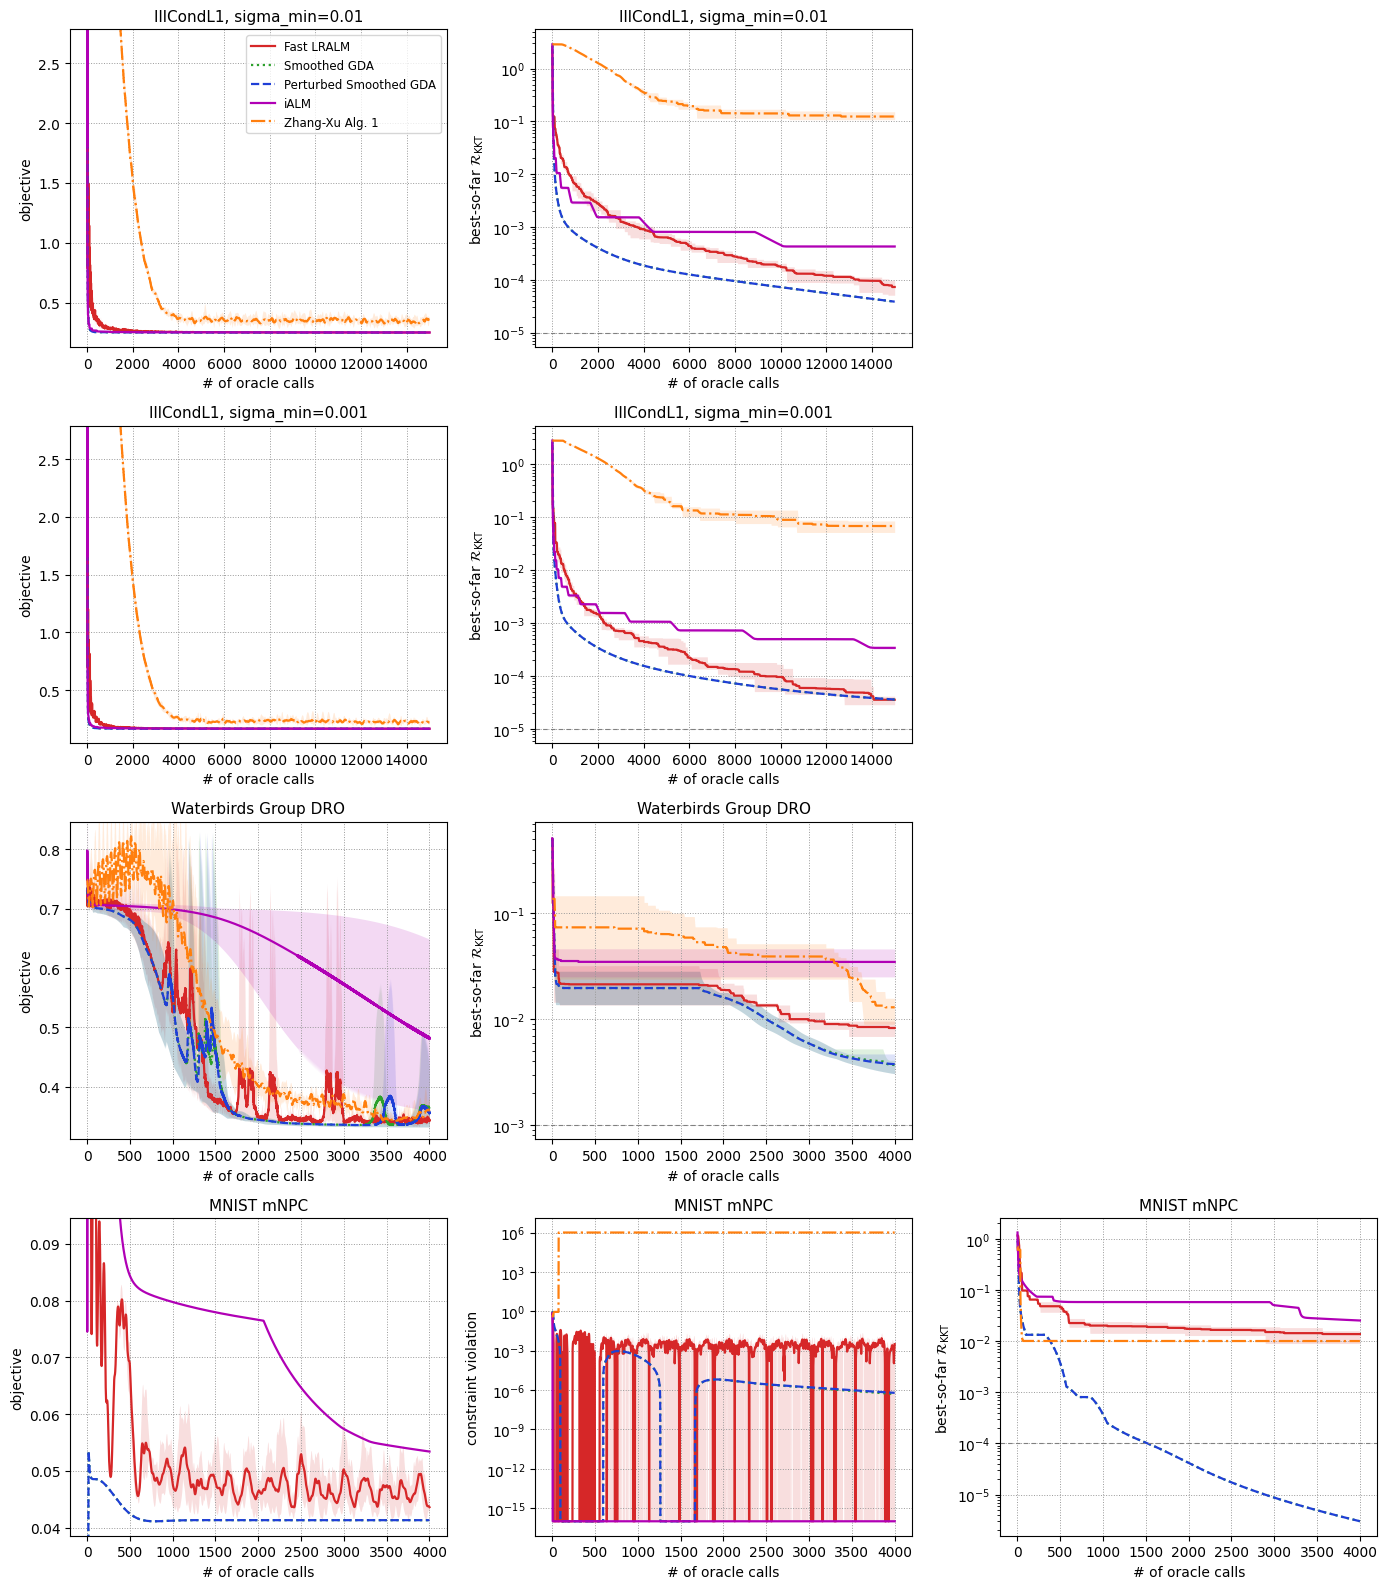

In [10]:
# 9. 作图：5 个初始点上的平均轨迹（实线）与最小–最大范围（阴影）；目标值、R_KKT、原约束违反度 vs oracle 调用次数
import matplotlib.pyplot as plt

STYLE = {
    "Fast LRALM":             ("#d62728", "-"),
    "Smoothed GDA":           ("#2ca02c", ":"),
    "Perturbed Smoothed GDA": ("#1f3fd6", "--"),
    "iALM":                   ("#b000b5", "-"),
    "Zhang-Xu Alg. 1":        ("#ff7f0e", "-."),
}
EXPS = [(f"illcond_{sm:.0e}_r5", f"IllCondL1, sigma_min={sm:g}", ILL_EPS, ILL_BUDGET, ("obj", "kkt")) for sm in ILL_SIGMAS] + [
        ("waterbirds_gdro_r5", "Waterbirds Group DRO", WB_EPS, WB_BUDGET, ("obj", "kkt")),
        ("mnist_mnpc_r5", "MNIST mNPC", MN_EPS, MN_BUDGET, ("obj", "cviol", "kkt"))]
LABEL = {"obj": "objective", "kkt": r"best-so-far $\mathcal{R}_{\mathrm{KKT}}$", "cviol": "constraint violation"}

fig, axes = plt.subplots(len(EXPS), 3, figsize=(14.0, 4.0 * len(EXPS)))
for i, (tag, title, eps, xmax, keys) in enumerate(EXPS):
    D = np.load(os.path.join(OUT_DIR, f"{tag}.npz"))
    for j in range(3):
        ax = axes[i, j]
        if j >= len(keys):
            ax.axis("off"); continue
        key = keys[j]
        grid = np.arange(1, xmax + 1)
        span = []
        for name, (col, ls) in STYLE.items():
            ys = []
            for sd in SEEDS:
                x = D[f"{name}|{sd}|calls"]; y = np.nan_to_num(D[f"{name}|{sd}|{key}"], nan=np.inf)
                if key == "kkt":
                    y = np.minimum.accumulate(y)
                idx = np.clip(np.searchsorted(x, grid), 0, len(x) - 1)
                ys.append(y[idx])
            ys = np.array(ys)
            if key != "obj":
                ys = np.clip(ys, 1e-16, 1e6)  # zero violation sits at the axis floor; divergent runs at the ceiling
            fin = np.isfinite(ys).all(axis=0)
            m, lo, hi = np.mean(ys, axis=0), np.min(ys, axis=0), np.max(ys, axis=0)
            (ax.semilogy if key != "obj" else ax.plot)(grid[fin], m[fin], color=col, ls=ls, lw=1.6, label=name)
            ax.fill_between(grid[fin], lo[fin], hi[fin], color=col, alpha=0.15, lw=0)
            tail = m[fin][len(grid) // 10:]
            if key == "obj" and fin.all() and len(tail) and np.max(tail) < 10 * abs(m[0]) + 1:
                span += [tail.min(), tail.max()]  # divergent runs are drawn but excluded from the y-range
        if key == "obj" and span:
            lo_, hi_ = min(span), max(span); pad = 0.05 * (hi_ - lo_ + 1e-12)
            ax.set_ylim(lo_ - pad, hi_ + pad)
        if key == "kkt":
            ax.axhline(eps, color="gray", lw=0.8, ls=(0, (4, 3)))
        ax.set_xlabel("# of oracle calls"); ax.set_ylabel(LABEL[key]); ax.set_title(title, fontsize=11)
        ax.grid(True, ls=":", lw=0.7, color="0.6")
        if i == 0 and j == 0:
            ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_experiments_r5.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "fig_experiments_r5.png"), dpi=130, bbox_inches="tight")
plt.show()
